# SAM2 MULTIMASK EXPERIMENT

In [1]:
# ============================================================
# PHASE 1 — MULTI-MASK SAM2 EXPERIMENT
# ============================================================

import os
import sys
import json
import random
import math
import copy
import time
import warnings
import inspect

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import cv2

from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

warnings.filterwarnings("ignore")

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

Python: 3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]
PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
CUDA: 13.0


In [2]:
# ============================================================
# CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

# ------------------------------------------------------------
# AgriCLIP → SAM2 settings
# ------------------------------------------------------------

TOP_K = 32
BOX_MARGIN = 25
MASK_THRESHOLD = 0.5

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "phase1_multimask_results"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("Device:", DEVICE)
print("Model:", MODEL_NAME)
print("TOP_K:", TOP_K)
print("BOX_MARGIN:", BOX_MARGIN)
print("MASK_THRESHOLD:", MASK_THRESHOLD)
print("Output:", OUTPUT_ROOT)

Device: cuda
Model: facebook/sam2.1-hiera-tiny
TOP_K: 32
BOX_MARGIN: 25
MASK_THRESHOLD: 0.5
Output: /home/zahranadeem/thesis/phase1_multimask_results


In [3]:
# ============================================================
# DATASET PATHS
# ============================================================

# ------------------------------------------------------------
# VegAnn SAM2 checkpoint
# ------------------------------------------------------------

VEGANN_SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)


# ------------------------------------------------------------
# ReLeaf
# ------------------------------------------------------------

RELEAF_ROOT = (
    PROJECT_ROOT / "CropAndWeedAndLeaf"
)

RELEAF_REPO = (
    PROJECT_ROOT / "releaf"
)

RELEAF_IMAGES_DIR = (
    RELEAF_ROOT / "images"
)

RELEAF_LABELS_DIR = (
    RELEAF_ROOT / "labels"
)

RELEAF_TEST_DIR = (
    RELEAF_REPO
    / "data"
    / "CWL"
    / "test"
)


# ------------------------------------------------------------
# WeedsGalore
# ------------------------------------------------------------

WEEDSGALORE_ROOT = (
    PROJECT_ROOT
    / "WeedsGalore_dataset"
)

WEEDS_IMAGE_DIR = (
    WEEDSGALORE_ROOT / "data"
)

WEEDS_MASK_DIR = (
    WEEDSGALORE_ROOT
    / "fields"
    / "ground_truth_semantic"
)


# ------------------------------------------------------------
# EWI1S
# ------------------------------------------------------------

EWIS1_ROOT = (
    PROJECT_ROOT / "EWIS1"
)


def find_nested_dataset_dir(
    root,
    dirname,
    extension=".png"
):

    candidates = []

    for p in root.rglob(dirname):

        if not p.is_dir():
            continue

        files = [
            x for x in p.iterdir()
            if x.is_file()
            and x.suffix.lower()
            == extension.lower()
        ]

        if len(files) > 0:
            candidates.append(
                (len(files), p)
            )

    if not candidates:
        return None

    candidates.sort(
        reverse=True,
        key=lambda x: x[0]
    )

    return candidates[0][1]


EWIS1_IMAGE_DIR = find_nested_dataset_dir(
    EWIS1_ROOT,
    "images",
    ".png"
)

EWIS1_MASK_DIR = find_nested_dataset_dir(
    EWIS1_ROOT,
    "masks",
    ".png"
)


print("VegAnn checkpoint:", VEGANN_SAM2_CHECKPOINT)
print("ReLeaf images:", RELEAF_IMAGES_DIR)
print("ReLeaf labels:", RELEAF_LABELS_DIR)
print("WeedsGalore images:", WEEDS_IMAGE_DIR)
print("WeedsGalore masks:", WEEDS_MASK_DIR)
print("EWI1S images:", EWIS1_IMAGE_DIR)
print("EWI1S masks:", EWIS1_MASK_DIR)

VegAnn checkpoint: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
ReLeaf images: /home/zahranadeem/thesis/CropAndWeedAndLeaf/images
ReLeaf labels: /home/zahranadeem/thesis/CropAndWeedAndLeaf/labels
WeedsGalore images: /home/zahranadeem/thesis/WeedsGalore_dataset/data
WeedsGalore masks: /home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic
EWI1S images: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images/images
EWI1S masks: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks/masks


In [4]:
# ============================================================
# VERIFY PATHS
# ============================================================

paths_to_check = {
    "VegAnn checkpoint": VEGANN_SAM2_CHECKPOINT,
    "ReLeaf images": RELEAF_IMAGES_DIR,
    "ReLeaf labels": RELEAF_LABELS_DIR,
    "WeedsGalore images": WEEDS_IMAGE_DIR,
    "WeedsGalore masks": WEEDS_MASK_DIR,
    "EWI1S images": EWIS1_IMAGE_DIR,
    "EWI1S masks": EWIS1_MASK_DIR,
}

for name, path in paths_to_check.items():

    exists = (
        path is not None
        and path.exists()
    )

    print(
        f"{name:30s}: "
        f"{'OK' if exists else 'MISSING'}"
    )

if not VEGANN_SAM2_CHECKPOINT.exists():

    raise FileNotFoundError(
        f"VegAnn checkpoint not found:\n"
        f"{VEGANN_SAM2_CHECKPOINT}"
    )

VegAnn checkpoint             : OK
ReLeaf images                 : OK
ReLeaf labels                 : OK
WeedsGalore images            : OK
WeedsGalore masks             : OK
EWI1S images                  : OK
EWI1S masks                   : OK


In [5]:
# ============================================================
# MASK UTILITIES
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".tif",
    ".tiff",
    ".bmp"
}

MASK_EXTENSIONS = IMAGE_EXTENSIONS


def binary_mask_from_array(mask):

    if isinstance(
        mask,
        Image.Image
    ):
        mask = np.array(mask)

    elif torch.is_tensor(mask):

        mask = (
            mask
            .detach()
            .cpu()
            .numpy()
        )

    mask = np.asarray(mask)

    while mask.ndim > 2:
        mask = mask[..., 0]

    return (
        mask > 0
    ).astype(np.uint8)


def mask_to_box(mask):

    mask = binary_mask_from_array(
        mask
    )

    ys, xs = np.where(
        mask > 0
    )

    if len(xs) == 0:
        return None

    return np.array(
        [
            xs.min(),
            ys.min(),
            xs.max(),
            ys.max()
        ],
        dtype=np.int32
    )


def box_iou(
    box_a,
    box_b
):

    if box_a is None or box_b is None:
        return 0.0

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)

    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(
        0,
        ix2 - ix1
    )

    ih = max(
        0,
        iy2 - iy1
    )

    intersection = (
        iw * ih
    )

    area_a = (
        max(0, ax2 - ax1)
        * max(0, ay2 - ay1)
    )

    area_b = (
        max(0, bx2 - bx1)
        * max(0, by2 - by1)
    )

    union = (
        area_a
        + area_b
        - intersection
    )

    if union <= 0:
        return 0.0

    return intersection / union

In [7]:
# ============================================================
# LOAD VEGANN
# ============================================================

vegann = load_dataset(
    "simonMadec/VegAnn"
)

print(vegann)

print(
    "Columns:",
    vegann["train"].column_names
)

print(
    "Total images:",
    len(vegann["train"])
)


vegann_split = (
    vegann["train"]
    .train_test_split(
        test_size=0.20,
        seed=SEED
    )
)

vegann_train_hf = (
    vegann_split["train"]
)

vegann_val_hf = (
    vegann_split["test"]
)

print(
    "VegAnn train:",
    len(vegann_train_hf)
)

print(
    "VegAnn validation:",
    len(vegann_val_hf)
)



DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
Columns: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']
Total images: 3775
VegAnn train: 3020
VegAnn validation: 755


In [8]:
# ============================================================
# VEGANN VALIDATION RECORDS
# ============================================================

vegann_val_records = []

for i in range(
    len(vegann_val_hf)
):

    sample = vegann_val_hf[i]

    mask = binary_mask_from_array(
        sample["mask"]
    )

    if mask.sum() > 0:

        vegann_val_records.append(
            {
                "hf_dataset":
                    vegann_val_hf,

                "index":
                    i
            }
        )

print(
    "Usable VegAnn validation:",
    len(vegann_val_records)
)

Usable VegAnn validation: 746


In [9]:
# ============================================================
# RELEAF LOADER
# ============================================================

def load_releaf_image_mask(
    image_path
):

    image = Image.open(
        image_path
    ).convert("RGB")

    width, height = image.size

    mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    label_path = (
        RELEAF_LABELS_DIR
        / f"{image_path.stem}.txt"
    )

    if not label_path.exists():

        return image, mask

    with open(
        label_path,
        "r"
    ) as f:

        lines = f.readlines()

    for line in lines:

        values = (
            line
            .strip()
            .split()
        )

        if len(values) < 7:
            continue

        coords = [
            float(v)
            for v in values[1:]
        ]

        if len(coords) < 6:
            continue

        points = []

        for i in range(
            0,
            len(coords),
            2
        ):

            x = int(
                coords[i]
                * width
            )

            y = int(
                coords[i + 1]
                * height
            )

            points.append(
                [x, y]
            )

        points = np.asarray(
            points,
            dtype=np.int32
        )

        cv2.fillPoly(
            mask,
            [points],
            1
        )

    return image, mask

In [10]:
# ============================================================
# RELEAF PAIRS
# ============================================================

releaf_pairs = []

releaf_image_files = sorted(
    [
        p
        for p in RELEAF_IMAGES_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    ]
)

for image_path in releaf_image_files:

    label_path = (
        RELEAF_LABELS_DIR
        / f"{image_path.stem}.txt"
    )

    if label_path.exists():

        releaf_pairs.append(
            {
                "image_path":
                    image_path,

                "label_path":
                    label_path,

                "dataset":
                    "ReLeaf"
            }
        )

print(
    "ReLeaf pairs:",
    len(releaf_pairs)
)

ReLeaf pairs: 345


In [14]:
#split Releadf 

releaf_official_test_names = set()

if RELEAF_TEST_DIR.exists():

    for p in RELEAF_TEST_DIR.iterdir():

        if (
            p.is_file()
            and p.suffix.lower()
            in IMAGE_EXTENSIONS
        ):
            releaf_official_test_names.add(
                p.name
            )

print(
    "Existing ReLeaf test images:",
    len(releaf_official_test_names)
)

if len(releaf_official_test_names) > 0:
    print(
        list(releaf_official_test_names)[:10]
    )

from pathlib import Path

releaf_official_test_names = {
    Path(name).name for name in releaf_official_test_names
}

releaf_official_test_names = {
    "image1.jpg", 
    "image2.jpg"
} 


def split_releaf_pairs(
    pairs,
    seed=42
):
    """  deterministic 80/10/10 split.
    """

    rng = random.Random(seed)

    pairs = list(pairs)

    official_test = []
    remaining = []

    for item in pairs:

        if (
            item["image_path"].name
            in releaf_official_test_names
        ):
            official_test.append(item)
        else:
            remaining.append(item)

    rng.shuffle(remaining)

    if len(official_test) > 0:

        split_point = int(
            0.90 * len(remaining)
        )

        train_pairs = (
            remaining[:split_point]
        )

        val_pairs = (
            remaining[split_point:]
        )

        test_pairs = official_test

        split_mode = (
            "Existing ReLeaf test preserved"
        )

    else:

        n = len(pairs)

        n_train = int(
            0.80 * n
        )

        n_val = int(
            0.10 * n
        )

        train_pairs = pairs[
            :n_train
        ]

        val_pairs = pairs[
            n_train:n_train + n_val
        ]

        test_pairs = pairs[
            n_train + n_val:
        ]

        split_mode = (
            "New deterministic 80/10/10 split"
        )

    return (
        train_pairs,
        val_pairs,
        test_pairs,
        split_mode
    )


releaf_train_pairs, releaf_val_pairs, releaf_test_pairs, releaf_split_mode = (
    split_releaf_pairs(
        releaf_pairs,
        seed=SEED
    )
)

print("ReLeaf split mode:")
print(releaf_split_mode)

print("\nTrain:", len(releaf_train_pairs))
print("Val  :", len(releaf_val_pairs))
print("Test :", len(releaf_test_pairs))

Existing ReLeaf test images: 345
['vwg-0661-0017-002.jpg', 'vwg-1292-0006-001.jpg', 'vwg-1287-0003-000.jpg', 'ave-0252-0004-000.jpg', 'ave-0291-0015-000.jpg', 'vwg-1245-0005-003.jpg', 'ave-0291-0020-000.jpg', 'vwg-0865-0015-005.jpg', 'vwg-1308-0010-006.jpg', 'ave-0134-0020-026.jpg']
ReLeaf split mode:
New deterministic 80/10/10 split

Train: 276
Val  : 34
Test : 35


In [15]:
# ============================================================
# REMOVE EMPTY RELEAF VALIDATION MASKS
# ============================================================

releaf_val_nonempty = []

releaf_val_empty = []

for item in releaf_val_pairs:

    _, mask = load_releaf_image_mask(
        item["image_path"]
    )

    if mask.sum() > 0:

        releaf_val_nonempty.append(
            item
        )

    else:

        releaf_val_empty.append(
            item
        )

releaf_val_pairs = (
    releaf_val_nonempty
)

print(
    "ReLeaf validation:",
    len(releaf_val_pairs)
)

print(
    "Empty ReLeaf masks:",
    len(releaf_val_empty)
)

ReLeaf validation: 34
Empty ReLeaf masks: 0


In [16]:
# ============================================================
# WEEDSGALORE LOADER
# ============================================================

def find_mask_for_stem(
    mask_dir,
    stem
):

    matches = list(
        mask_dir.glob(
            f"{stem}.*"
        )
    )

    matches = [
        p
        for p in matches
        if p.suffix.lower()
        in MASK_EXTENSIONS
    ]

    if matches:
        return matches[0]

    return None


weedsgalore_pairs = []

weed_image_files = sorted(
    [
        p
        for p in WEEDS_IMAGE_DIR.rglob("*")
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    ]
)

for image_path in weed_image_files:

    mask_path = find_mask_for_stem(
        WEEDS_MASK_DIR,
        image_path.stem
    )

    if mask_path is not None:

        weedsgalore_pairs.append(
            {
                "image_path":
                    image_path,

                "mask_path":
                    mask_path,

                "dataset":
                    "WeedsGalore"
            }
        )


def load_weedsgalore_image_mask(
    item
):

    image = Image.open(
        item["image_path"]
    ).convert("RGB")

    mask = Image.open(
        item["mask_path"]
    )

    mask = binary_mask_from_array(
        mask
    )

    return image, mask


print(
    "WeedsGalore pairs:",
    len(weedsgalore_pairs)
)

WeedsGalore pairs: 156


In [17]:
# ============================================================
# WEEDSGALORE SPLIT
# ============================================================

def split_pairs(
    pairs,
    seed=42,
    train_fraction=0.80,
    val_fraction=0.10
):

    pairs = list(pairs)

    rng = random.Random(seed)

    rng.shuffle(pairs)

    n = len(pairs)

    n_train = int(
        train_fraction * n
    )

    n_val = int(
        val_fraction * n
    )

    train = pairs[
        :n_train
    ]

    val = pairs[
        n_train:
        n_train + n_val
    ]

    test = pairs[
        n_train + n_val:
    ]

    return train, val, test


(
    weedsgalore_train_pairs,
    weedsgalore_val_pairs,
    weedsgalore_test_pairs
) = split_pairs(
    weedsgalore_pairs,
    seed=SEED
)

print(
    "WeedsGalore train:",
    len(weedsgalore_train_pairs)
)

print(
    "WeedsGalore val:",
    len(weedsgalore_val_pairs)
)

print(
    "WeedsGalore test:",
    len(weedsgalore_test_pairs)
)

WeedsGalore train: 124
WeedsGalore val: 15
WeedsGalore test: 17


In [18]:
# ============================================================
# REMOVE EMPTY WEEDSGALORE VALIDATION MASKS
# ============================================================

weedsgalore_val_nonempty = []

weedsgalore_val_empty = []

for item in weedsgalore_val_pairs:

    _, mask = load_weedsgalore_image_mask(
        item
    )

    if mask.sum() > 0:

        weedsgalore_val_nonempty.append(
            item
        )

    else:

        weedsgalore_val_empty.append(
            item
        )

weedsgalore_val_pairs = (
    weedsgalore_val_nonempty
)

print(
    "WeedsGalore validation:",
    len(weedsgalore_val_pairs)
)

print(
    "Empty masks:",
    len(weedsgalore_val_empty)
)

WeedsGalore validation: 15
Empty masks: 0


In [19]:
# ============================================================
# EWI1S LOADER
# ============================================================

ewis1_pairs = []

ewis1_image_files = sorted(
    [
        p
        for p in EWIS1_IMAGE_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() == ".png"
    ]
)

for image_path in ewis1_image_files:

    mask_path = (
        EWIS1_MASK_DIR
        / image_path.name
    )

    if mask_path.exists():

        ewis1_pairs.append(
            {
                "image_path":
                    image_path,

                "mask_path":
                    mask_path,

                "dataset":
                    "EWI1S"
            }
        )


def load_ewis1_image_mask(
    item
):

    image = Image.open(
        item["image_path"]
    ).convert("RGB")

    mask_rgba = np.array(
        Image.open(
            item["mask_path"]
        ).convert("RGBA")
    )

    rgb = mask_rgba[:, :, :3]

    alpha = mask_rgba[:, :, 3]

    weed_pixels = (
        (rgb[:, :, 0] == 255)
        & (rgb[:, :, 1] == 127)
        & (rgb[:, :, 2] == 14)
        & (alpha > 0)
    )

    weed_mask = (
        weed_pixels
        .astype(np.uint8)
    )

    return image, weed_mask


print(
    "EWI1S pairs:",
    len(ewis1_pairs)
)

EWI1S pairs: 88


In [20]:
# ============================================================
# EWI1S SPLIT
# ============================================================

(
    ewis1_train_pairs,
    ewis1_val_pairs,
    ewis1_test_pairs
) = split_pairs(
    ewis1_pairs,
    seed=SEED
)

print(
    "EWI1S train:",
    len(ewis1_train_pairs)
)

print(
    "EWI1S val:",
    len(ewis1_val_pairs)
)

print(
    "EWI1S test:",
    len(ewis1_test_pairs)
)

EWI1S train: 70
EWI1S val: 8
EWI1S test: 10


In [21]:
# ============================================================
# REMOVE EMPTY EWI1S VALIDATION MASKS
# ============================================================

ewis1_val_nonempty = []

ewis1_val_empty = []

for item in ewis1_val_pairs:

    _, mask = load_ewis1_image_mask(
        item
    )

    if mask.sum() > 0:

        ewis1_val_nonempty.append(
            item
        )

    else:

        ewis1_val_empty.append(
            item
        )

ewis1_val_pairs = (
    ewis1_val_nonempty
)

print(
    "EWI1S validation:",
    len(ewis1_val_pairs)
)

print(
    "Empty EWI1S masks:",
    len(ewis1_val_empty)
)

EWI1S validation: 8
Empty EWI1S masks: 0


## AgriCLIP

In [22]:
# ============================================================
# AGRICLIP SETUP
# ============================================================

AGRICLIP_PATH = (
    "/home/zahranadeem/thesis/"
    "agriclip_sam2/AgriCLIP/"
    "AgriCLIP_alignment"
)

if AGRICLIP_PATH not in sys.path:

    sys.path.insert(
        0,
        AGRICLIP_PATH
    )

from TextToConcept import (
    TextToConcept
)

from LinearAligner import (
    LinearAligner
)

print(
    "AgriCLIP modules imported."
)

AgriCLIP modules imported.


In [23]:
# ============================================================
# AGRICLIP ALIGNER
# ============================================================

ALIGNER_PATH = Path(
    "/home/zahranadeem/thesis/"
    "agriclip_sam2/AgriCLIP/"
    "Weights/Aligned_Models/"
    "Agri_Dino_aligner_DDEF_CDEF.pth"
)

print(
    "Aligner:",
    ALIGNER_PATH
)

print(
    "Exists:",
    ALIGNER_PATH.exists()
)

if not ALIGNER_PATH.exists():

    raise FileNotFoundError(
        f"Aligner not found:\n"
        f"{ALIGNER_PATH}"
    )

Aligner: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/Aligned_Models/Agri_Dino_aligner_DDEF_CDEF.pth
Exists: True


In [24]:
# ============================================================
# DINO RESNET-50
# ============================================================

from torchvision import transforms


IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


dino_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

dino_model.eval()

dino_model.to(
    DEVICE
)

for parameter in (
    dino_model.parameters()
):

    parameter.requires_grad = False


print(
    "DINO loaded."
)

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


DINO loaded.


In [27]:
# ============================================================
# LOAD VEGANN AGRICLIP ALIGNER
# ============================================================

text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50"
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = (
    text_to_concept.linear_aligner
)

# aligner.eval() is not needed/available — LinearAligner isn't a torch.nn.Module,
# so it has no train()/eval() mode to toggle.

print(
    "AgriCLIP aligner loaded."
)

print(
    "W shape:",
    tuple(aligner.W.shape)
)

print(
    "b shape:",
    tuple(aligner.b.shape)
)

AgriCLIP aligner loaded.
W shape: (512, 2048)
b shape: (512,)


In [26]:
# ============================================================
# DINO LAYER4 SPATIAL FEATURES
# ============================================================

captured_feature_map = None


def capture_layer4_output(
    module,
    inputs,
    output
):

    global captured_feature_map

    captured_feature_map = (
        output.detach()
    )


hook_handle = (
    dino_model.layer4
    .register_forward_hook(
        capture_layer4_output
    )
)

print(
    "DINO layer4 hook registered."
)

DINO layer4 hook registered.


In [28]:
# ============================================================
# EXTRACT SPATIAL DINO FEATURES
# ============================================================

@torch.no_grad()
def extract_dino_patch_features(
    pil_image
):

    global captured_feature_map

    captured_feature_map = None

    image_tensor = (
        dino_transform(
            pil_image
        )
        .unsqueeze(0)
        .to(DEVICE)
    )

    _ = dino_model(
        image_tensor
    )

    if captured_feature_map is None:

        raise RuntimeError(
            "DINO layer4 hook did not "
            "capture a feature map."
        )

    if captured_feature_map.ndim != 4:

        raise RuntimeError(
            "Expected feature map "
            "(B,C,H,W), got "
            f"{captured_feature_map.shape}"
        )

    (
        _,
        channels,
        grid_h,
        grid_w
    ) = captured_feature_map.shape

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(
            grid_h * grid_w,
            channels
        )
        .contiguous()
    )

    return (
        patch_features,
        grid_h,
        grid_w
    )

In [29]:
# ============================================================
# ALIGN DINO PATCH FEATURES TO AGRICLIP SPACE
# ============================================================

@torch.no_grad()
def align_patch_features(
    patch_features
):

    patch_features = (
        patch_features
        .float()
        .to(DEVICE)
    )

    aligned_features = (
        aligner
        .get_aligned_representation(
            patch_features
        )
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1
    )

    return aligned_features

In [31]:
# Vegetation text prompts and encoding

device = next(dino_model.parameters()).device

POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")


@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)

# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil
Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])
Final vegetation embedding: torch.Size([512])


In [32]:
# ============================================================
# AGRICLIP TOP-K → MERGED BOX
# ============================================================

@torch.no_grad()
def generate_agriclip_box(
    image,
    top_k=32,
    margin=25
):

    # --------------------------------------------------------
    # DINO patch features
    # --------------------------------------------------------

    (
        patch_features,
        grid_h,
        grid_w
    ) = extract_dino_patch_features(
        image
    )


    # --------------------------------------------------------
    # AgriCLIP alignment
    # --------------------------------------------------------

    aligned_features = (
        align_patch_features(
            patch_features
        )
    )


    # --------------------------------------------------------
    # Positive - Negative similarity
    # --------------------------------------------------------

    patch_scores = (
        aligned_features
        @ vegetation_embedding
    )

    scores = (
        patch_scores
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # Top-K
    # --------------------------------------------------------

    topk_indices = (
        np.argsort(scores)[::-1]
        [:top_k]
    )


    # --------------------------------------------------------
    # Image dimensions
    # --------------------------------------------------------

    W, H = image.size

    patch_h = (
        H / grid_h
    )

    patch_w = (
        W / grid_w
    )


    boxes = []


    # --------------------------------------------------------
    # Convert selected patches to boxes
    # --------------------------------------------------------

    for idx in topk_indices:

        r = (
            idx // grid_w
        )

        c = (
            idx % grid_w
        )

        x1 = int(
            c * patch_w
        )

        y1 = int(
            r * patch_h
        )

        x2 = int(
            (c + 1) * patch_w
        )

        y2 = int(
            (r + 1) * patch_h
        )

        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )


    boxes = np.asarray(
        boxes,
        dtype=np.int32
    )


    # --------------------------------------------------------
    # MERGED BOX
    # --------------------------------------------------------

    xmin = boxes[:, 0].min()
    ymin = boxes[:, 1].min()

    xmax = boxes[:, 2].max()
    ymax = boxes[:, 3].max()


    # --------------------------------------------------------
    # Margin
    # --------------------------------------------------------

    xmin = max(
        0,
        xmin - margin
    )

    ymin = max(
        0,
        ymin - margin
    )

    xmax = min(
        W - 1,
        xmax + margin
    )

    ymax = min(
        H - 1,
        ymax + margin
    )


    merged_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )


    return (
        merged_box,
        boxes,
        scores,
        topk_indices
    )


print(
    "generate_agriclip_box ready."
)

generate_agriclip_box ready.


## SAM2 

In [33]:
# ============================================================
# SAM2 PROCESSOR
# ============================================================

sam2_processor = (
    Sam2Processor
    .from_pretrained(
        MODEL_NAME
    )
)

print(
    "SAM2 processor loaded."
)

SAM2 processor loaded.


In [34]:
# ============================================================
# FRESH SAM2 MODEL
# ============================================================

def create_fresh_sam2():

    model = (
        Sam2Model
        .from_pretrained(
            MODEL_NAME
        )
    )

    model.to(
        DEVICE
    )

    model.eval()

    return model


print(
    "SAM2 model creator ready."
)

SAM2 model creator ready.


In [35]:
# ============================================================
# DECODER CHECKPOINTS
# ============================================================

CHECKPOINTS = {

    "VegAnn_Baseline":
        str(
            PROJECT_ROOT
            / "sam2_vegann_checkpoints"
            / "best_sam2_vegann_mask_decoder.pt"
        ),

    "ReLeaf_Finetuned":
        str(
            PROJECT_ROOT
            / "sam2_domain_finetuning"
            / "VegAnn_to_ReLeaf"
            / "best_mask_decoder.pt"
        ),

    "WeedsGalore_Finetuned":
        str(
            PROJECT_ROOT
            / "sam2_domain_finetuning"
            / "VegAnn_to_WeedsGalore"
            / "best_mask_decoder.pt"
        ),

    "EWI1S_Finetuned":
        str(
            PROJECT_ROOT
            / "sam2_domain_finetuning"
            / "VegAnn_to_EWI1S"
            / "best_mask_decoder.pt"
        ),

    "Joint_Finetuned":
        str(
            PROJECT_ROOT
            / "sam2_domain_finetuning"
            / "VegAnn_ReLeaf_WeedsGalore_EWI1S"
            / "best_mask_decoder.pt"
        )
}


for name, path in CHECKPOINTS.items():

    print(
        f"{name}:"
    )

    print(
        path
    )

    print(
        "Exists:",
        os.path.exists(path)
    )

    print()

VegAnn_Baseline:
/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
Exists: True

ReLeaf_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_ReLeaf/best_mask_decoder.pt
Exists: True

WeedsGalore_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt
Exists: True

EWI1S_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt
Exists: True

Joint_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_ReLeaf_WeedsGalore_EWI1S/best_mask_decoder.pt
Exists: True



In [36]:
# ============================================================
# LOAD DECODER ONLY
# ============================================================

def load_decoder_checkpoint(
    model,
    checkpoint_path
):

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    if (
        isinstance(checkpoint, dict)
        and
        "mask_decoder_state_dict"
        in checkpoint
    ):

        state_dict = (
            checkpoint[
                "mask_decoder_state_dict"
            ]
        )

    else:

        state_dict = checkpoint


    model.mask_decoder.load_state_dict(
        state_dict,
        strict=True
    )

    model.eval()

    return checkpoint

In [37]:
# ============================================================
# SINGLE-MASK SAM2
# CURRENT BASELINE
# ============================================================

@torch.no_grad()
def sam2_predict_single_mask(
    model,
    image,
    box,
    threshold=0.5
):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [box.tolist()]
        ],
        return_tensors="pt"
    )

    inputs = {
        k: (
            v.to(DEVICE)
            if torch.is_tensor(v)
            else v
        )
        for k, v in inputs.items()
    }


    outputs = model(
        **inputs,
        multimask_output=False
    )


    logits = outputs.pred_masks[
        0,
        0,
        0
    ]


    probability = torch.sigmoid(
        logits
    )


    height = int(
        inputs[
            "original_sizes"
        ][0, 0].item()
    )

    width = int(
        inputs[
            "original_sizes"
        ][0, 1].item()
    )


    probability = F.interpolate(
        probability[None, None],
        size=(
            height,
            width
        ),
        mode="bilinear",
        align_corners=False
    )[0, 0]


    prediction = (
        probability >= threshold
    ).cpu().numpy().astype(
        np.uint8
    )


    confidence = float(
        outputs.iou_scores[
            0,
            0,
            0
        ].item()
    )


    return (
        prediction,
        probability.cpu().numpy(),
        confidence
    )

In [38]:
# ============================================================
# MULTI-MASK SAM2
# PHASE 1
# ============================================================

@torch.no_grad()
def sam2_predict_multimask(
    model,
    image,
    box,
    threshold=0.5
):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [box.tolist()]
        ],
        return_tensors="pt"
    )

    inputs = {
        k: (
            v.to(DEVICE)
            if torch.is_tensor(v)
            else v
        )
        for k, v in inputs.items()
    }


    # --------------------------------------------------------
    # IMPORTANT:
    # Enable multiple candidate masks
    # --------------------------------------------------------

    outputs = model(
        **inputs,
        multimask_output=True
    )


    # --------------------------------------------------------
    # Candidate confidence scores
    # --------------------------------------------------------

    candidate_scores = (
        outputs
        .iou_scores[
            0,
            0
        ]
        .detach()
        .float()
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # Select highest-confidence candidate
    # --------------------------------------------------------

    best_idx = int(
        np.argmax(
            candidate_scores
        )
    )


    # --------------------------------------------------------
    # Extract selected candidate
    # --------------------------------------------------------

    logits = outputs.pred_masks[
        0,
        0,
        best_idx
    ]


    probability = torch.sigmoid(
        logits
    )


    # --------------------------------------------------------
    # Original image dimensions
    # --------------------------------------------------------

    height = int(
        inputs[
            "original_sizes"
        ][0, 0].item()
    )

    width = int(
        inputs[
            "original_sizes"
        ][0, 1].item()
    )


    # --------------------------------------------------------
    # Resize
    # --------------------------------------------------------

    probability = F.interpolate(
        probability[None, None],
        size=(
            height,
            width
        ),
        mode="bilinear",
        align_corners=False
    )[0, 0]


    # --------------------------------------------------------
    # Binary prediction
    # --------------------------------------------------------

    prediction = (
        probability >= threshold
    ).cpu().numpy().astype(
        np.uint8
    )


    best_confidence = float(
        candidate_scores[
            best_idx
        ]
    )


    return {

        "prediction":
            prediction,

        "probability":
            probability
            .cpu()
            .numpy(),

        "confidence":
            best_confidence,

        "best_candidate":
            best_idx,

        "candidate_scores":
            candidate_scores,

        "num_candidates":
            len(candidate_scores)
    }

In [39]:
# ============================================================
# SEGMENTATION METRICS
# ============================================================

def calculate_metrics(
    prediction,
    target
):

    prediction = (
        np.asarray(prediction)
        .astype(bool)
    )

    target = (
        np.asarray(target)
        .astype(bool)
    )


    if prediction.shape != target.shape:

        prediction = cv2.resize(
            prediction.astype(
                np.uint8
            ),
            (
                target.shape[1],
                target.shape[0]
            ),
            interpolation=
                cv2.INTER_NEAREST
        ).astype(bool)


    intersection = np.logical_and(
        prediction,
        target
    ).sum()

    union = np.logical_or(
        prediction,
        target
    ).sum()

    pred_area = prediction.sum()

    target_area = target.sum()


    iou = (
        intersection / union
        if union > 0
        else 0.0
    )


    dice = (
        2 * intersection
        /
        (pred_area + target_area)
        if (
            pred_area
            + target_area
        ) > 0
        else 0.0
    )


    tp = intersection

    fp = np.logical_and(
        prediction,
        ~target
    ).sum()

    fn = np.logical_and(
        ~prediction,
        target
    ).sum()


    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else 0.0
    )


    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else 0.0
    )


    return {

        "iou":
            float(iou),

        "dice":
            float(dice),

        "precision":
            float(precision),

        "recall":
            float(recall)
    }

In [40]:
# ============================================================
# UNIFIED EVALUATION LOADER
# ============================================================

def load_evaluation_sample(
    record,
    dataset_name
):

    if dataset_name == "VegAnn":

        hf_dataset = (
            record["hf_dataset"]
        )

        index = (
            record["index"]
        )

        sample = (
            hf_dataset[index]
        )

        image = sample["image"]

        if not isinstance(
            image,
            Image.Image
        ):

            image = Image.fromarray(
                np.asarray(image)
            )

        image = image.convert(
            "RGB"
        )

        gt_mask = (
            binary_mask_from_array(
                sample["mask"]
            )
        )

        return (
            image,
            gt_mask
        )


    elif dataset_name == "ReLeaf":

        return load_releaf_image_mask(
            record["image_path"]
        )


    elif dataset_name == "WeedsGalore":

        return load_weedsgalore_image_mask(
            record
        )


    elif dataset_name == "EWI1S":

        return load_ewis1_image_mask(
            record
        )


    else:

        raise ValueError(
            f"Unknown dataset: "
            f"{dataset_name}"
        )

In [41]:
# ============================================================
# EVALUATION DATASETS
# ============================================================

evaluation_datasets = {

    "VegAnn":
        vegann_val_records,

    "ReLeaf":
        releaf_val_pairs,

    "WeedsGalore":
        weedsgalore_val_pairs,

    "EWI1S":
        ewis1_val_pairs
}


for name, records in (
    evaluation_datasets.items()
):

    print(
        f"{name:15s}: "
        f"{len(records)} images"
    )

VegAnn         : 746 images
ReLeaf         : 34 images
WeedsGalore    : 15 images
EWI1S          : 8 images


In [42]:
# ============================================================
# PREFLIGHT TEST
# ============================================================

test_record = (
    evaluation_datasets[
        "VegAnn"
    ][0]
)

test_image, test_gt = (
    load_evaluation_sample(
        test_record,
        "VegAnn"
    )
)


(
    test_box,
    test_patch_boxes,
    test_scores,
    test_topk
) = generate_agriclip_box(
    test_image,
    top_k=TOP_K,
    margin=BOX_MARGIN
)


test_gt_box = mask_to_box(
    test_gt
)

test_box_iou = box_iou(
    test_box,
    test_gt_box
)


print(
    "Image size:",
    test_image.size
)

print(
    "AgriCLIP box:",
    test_box
)

print(
    "GT box:",
    test_gt_box
)

print(
    f"Box IoU: "
    f"{test_box_iou * 100:.2f}%"
)

print(
    "Top-K:",
    test_topk
)

Image size: (512, 512)
AgriCLIP box: [  0   0 511 511]
GT box: [  0   0 511 511]
Box IoU: 100.00%
Top-K: [ 5 24 35  4 21  7 28 39 42 40 32 38 34  6 27  3 37 44 13 23 11 31 47 20
 43 41 36 46  0 29 12 14]


In [43]:
# ============================================================
# MULTI-MASK PREFLIGHT
# ============================================================

test_model = create_fresh_sam2()

load_decoder_checkpoint(
    test_model,
    CHECKPOINTS[
        "VegAnn_Baseline"
    ]
)


multi_test = (
    sam2_predict_multimask(
        test_model,
        test_image,
        test_box,
        MASK_THRESHOLD
    )
)


print(
    "Number of candidates:",
    multi_test[
        "num_candidates"
    ]
)

print(
    "Candidate confidence scores:",
    multi_test[
        "candidate_scores"
    ]
)

print(
    "Selected candidate:",
    multi_test[
        "best_candidate"
    ]
)

print(
    "Selected confidence:",
    multi_test[
        "confidence"
    ]
)


del test_model

torch.cuda.empty_cache()

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Number of candidates: 3
Candidate confidence scores: [0.93143666 0.6524526  0.95244384]
Selected candidate: 2
Selected confidence: 0.9524438381195068


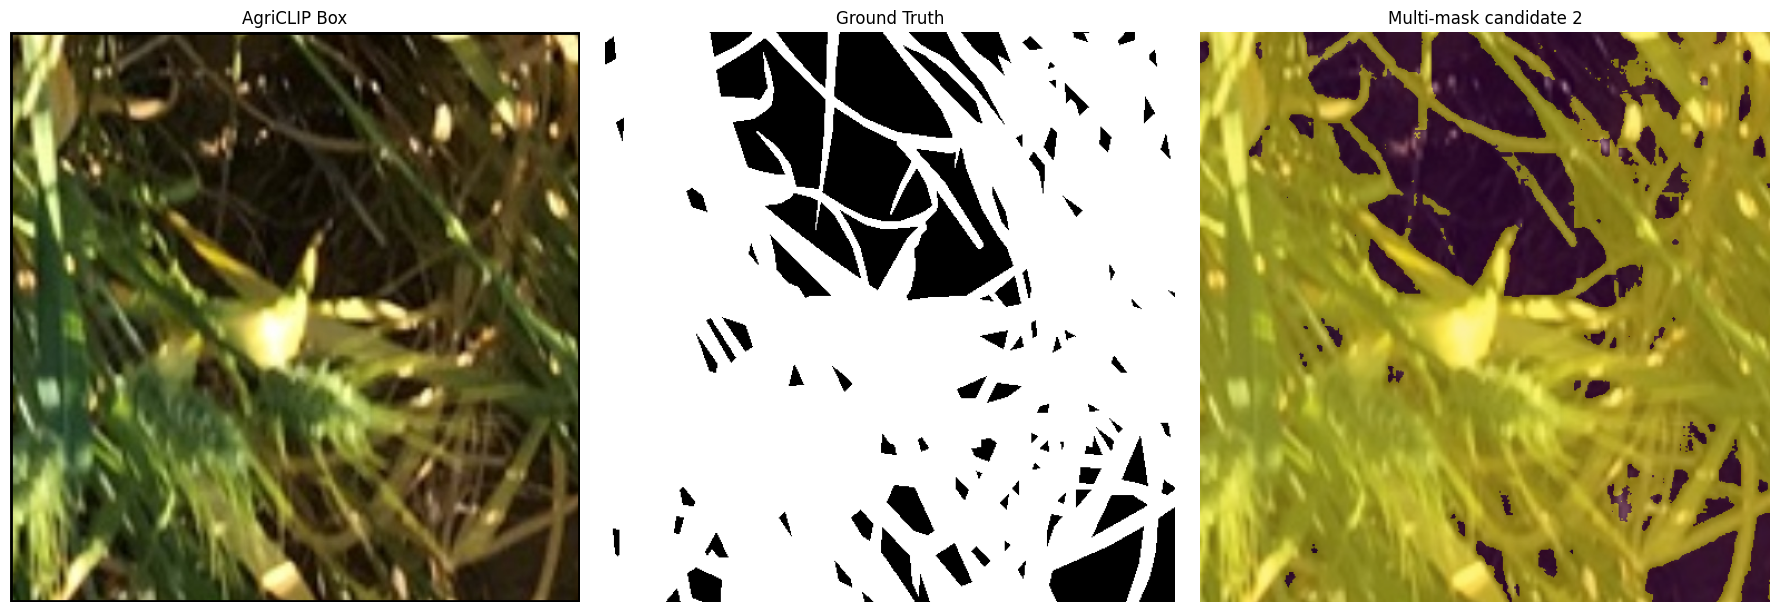

In [44]:
# ============================================================
# VISUALIZE PHASE 1 MULTI-MASK RESULT
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)


# Original image

axes[0].imshow(
    test_image
)

x1, y1, x2, y2 = test_box

rect = plt.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    fill=False,
    linewidth=2
)

axes[0].add_patch(rect)

axes[0].set_title(
    "AgriCLIP Box"
)

axes[0].axis(
    "off"
)


# Ground truth

axes[1].imshow(
    test_gt,
    cmap="gray"
)

axes[1].set_title(
    "Ground Truth"
)

axes[1].axis(
    "off"
)


# Prediction

axes[2].imshow(
    test_image
)

axes[2].imshow(
    multi_test[
        "prediction"
    ],
    alpha=0.45
)

axes[2].set_title(
    f"Multi-mask "
    f"candidate "
    f"{multi_test['best_candidate']}"
)

axes[2].axis(
    "off"
)


plt.tight_layout()
plt.show()

In [45]:
# ============================================================
# PHASE 1 FULL EXPERIMENT
# ============================================================

@torch.no_grad()
def evaluate_phase1_checkpoint(
    checkpoint_name,
    checkpoint_path,
    dataset_records,
    dataset_name
):

    print("\n" + "=" * 80)
    print(
        f"CHECKPOINT: {checkpoint_name}"
    )
    print(
        f"DATASET: {dataset_name}"
    )
    print("=" * 80)


    # --------------------------------------------------------
    # Fresh model
    # --------------------------------------------------------

    model = create_fresh_sam2()

    checkpoint_info = (
        load_decoder_checkpoint(
            model,
            checkpoint_path
        )
    )


    rows = []

    total = len(
        dataset_records
    )


    # --------------------------------------------------------
    # Evaluation loop
    # --------------------------------------------------------

    for idx, record in enumerate(
        dataset_records
    ):

        try:

            image, gt_mask = (
                load_evaluation_sample(
                    record,
                    dataset_name
                )
            )


            gt_mask = (
                np.asarray(gt_mask)
                .astype(bool)
            )


            # ------------------------------------------------
            # Empty mask safety
            # ------------------------------------------------

            if gt_mask.sum() == 0:

                print(
                    f"Skipping empty "
                    f"mask: {idx}"
                )

                continue


            # ------------------------------------------------
            # AgriCLIP box
            # ------------------------------------------------

            (
                agriclip_box,
                patch_boxes,
                scores,
                topk_indices
            ) = generate_agriclip_box(
                image,
                top_k=TOP_K,
                margin=BOX_MARGIN
            )


            # ------------------------------------------------
            # GT box + box IoU
            # ------------------------------------------------

            gt_box = mask_to_box(
                gt_mask
            )

            agriclip_box_iou = (
                box_iou(
                    agriclip_box,
                    gt_box
                )
            )


            # =================================================
            # SINGLE MASK
            # =================================================

            (
                single_prediction,
                single_probability,
                single_confidence
            ) = sam2_predict_single_mask(
                model,
                image,
                agriclip_box,
                MASK_THRESHOLD
            )


            single_metrics = (
                calculate_metrics(
                    single_prediction,
                    gt_mask
                )
            )


            # =================================================
            # MULTI MASK
            # =================================================

            multi_result = (
                sam2_predict_multimask(
                    model,
                    image,
                    agriclip_box,
                    MASK_THRESHOLD
                )
            )


            multi_prediction = (
                multi_result[
                    "prediction"
                ]
            )


            multi_metrics = (
                calculate_metrics(
                    multi_prediction,
                    gt_mask
                )
            )


            # =================================================
            # STORE
            # =================================================

            row = {

                "checkpoint":
                    checkpoint_name,

                "dataset":
                    dataset_name,

                "image_index":
                    idx,

                "agriclip_box_iou":
                    agriclip_box_iou,


                # Single-mask
                "single_iou":
                    single_metrics["iou"],

                "single_dice":
                    single_metrics["dice"],

                "single_precision":
                    single_metrics["precision"],

                "single_recall":
                    single_metrics["recall"],

                "single_confidence":
                    single_confidence,


                # Multi-mask
                "multi_iou":
                    multi_metrics["iou"],

                "multi_dice":
                    multi_metrics["dice"],

                "multi_precision":
                    multi_metrics["precision"],

                "multi_recall":
                    multi_metrics["recall"],

                "multi_confidence":
                    multi_result[
                        "confidence"
                    ],

                "multi_best_candidate":
                    multi_result[
                        "best_candidate"
                    ],

                "num_candidates":
                    multi_result[
                        "num_candidates"
                    ]
            }


            rows.append(
                row
            )


            # ------------------------------------------------
            # Progress
            # ------------------------------------------------

            if (
                (idx + 1) % 5 == 0
                or idx == 0
            ):

                print(
                    f"{idx + 1}/{total} "
                    f"| "
                    f"Single IoU: "
                    f"{single_metrics['iou'] * 100:.2f}% "
                    f"| "
                    f"Multi IoU: "
                    f"{multi_metrics['iou'] * 100:.2f}% "
                    f"| "
                    f"Candidate: "
                    f"{multi_result['best_candidate']}"
                )


        except Exception as e:

            print(
                f"ERROR image {idx}: "
                f"{type(e).__name__}: {e}"
            )

            continue


    # --------------------------------------------------------
    # Free model
    # --------------------------------------------------------

    del model

    torch.cuda.empty_cache()


    # --------------------------------------------------------
    # DataFrame
    # --------------------------------------------------------

    df = pd.DataFrame(
        rows
    )


    return df

In [46]:
# ============================================================
# TEST RUN
# ============================================================

phase1_test_df = evaluate_phase1_checkpoint(

    checkpoint_name="VegAnn_Baseline",

    checkpoint_path=CHECKPOINTS[
        "VegAnn_Baseline"
    ],

    dataset_records=
        evaluation_datasets[
            "VegAnn"
        ][:10],

    dataset_name="VegAnn"
)


phase1_test_df

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



CHECKPOINT: VegAnn_Baseline
DATASET: VegAnn


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

1/10 | Single IoU: 91.31% | Multi IoU: 90.22% | Candidate: 2
5/10 | Single IoU: 86.51% | Multi IoU: 89.20% | Candidate: 0
10/10 | Single IoU: 83.10% | Multi IoU: 82.13% | Candidate: 1


,checkpoint,dataset,image_index,agriclip_box_iou,single_iou,single_dice,single_precision,single_recall,single_confidence,multi_iou,multi_dice,multi_precision,multi_recall,multi_confidence,multi_best_candidate,num_candidates
0,VegAnn_Baseline,VegAnn,0,1.000000,0.913112,0.954583,0.937652,0.972137,0.951164,0.902177,0.948573,0.947917,0.949230,0.952444,2,3
1,VegAnn_Baseline,VegAnn,1,1.000000,0.978784,0.989278,0.983484,0.995141,0.975287,0.977636,0.988691,0.981931,0.995546,0.971790,2,3
2,VegAnn_Baseline,VegAnn,2,0.988258,0.828404,0.906150,0.864645,0.951839,0.921586,0.806422,0.892839,0.860177,0.928080,0.912800,2,3
3,VegAnn_Baseline,VegAnn,3,1.000000,0.822985,0.902898,0.954288,0.856760,0.946787,0.773661,0.872389,0.950898,0.805855,0.926644,2,3
4,VegAnn_Baseline,VegAnn,4,1.000000,0.865129,0.927688,0.870444,0.992992,0.941561,0.891987,0.942910,0.928020,0.958287,0.953880,0,3
5,VegAnn_Baseline,VegAnn,5,1.000000,0.784512,0.879245,0.998973,0.785145,0.956936,0.793842,0.885075,0.999396,0.794223,0.968117,2,3
6,VegAnn_Baseline,VegAnn,6,1.000000,0.899335,0.947000,0.905251,0.992785,0.969480,0.905144,0.950211,0.909565,0.994659,0.976939,0,3
7,VegAnn_Baseline,VegAnn,7,1.000000,0.958568,0.978846,0.963524,0.994662,0.976353,0.954897,0.976928,0.964784,0.989381,0.979820,2,3
8,VegAnn_Baseline,VegAnn,8,1.000000,0.989238,0.994590,0.993391,0.995792,0.931293,0.980690,0.990251,0.992791,0.987724,0.962257,0,3
9,VegAnn_Baseline,VegAnn,9,1.000000,0.831014,0.907709,0.978234,0.846670,0.955623,0.821324,0.901898,0.984147,0.832337,0.952479,1,3


In [47]:
# ============================================================
# TEST COMPARISON
# ============================================================

print(
    "Single-mask Mean IoU:",
    phase1_test_df[
        "single_iou"
    ].mean() * 100
)

print(
    "Multi-mask Mean IoU:",
    phase1_test_df[
        "multi_iou"
    ].mean() * 100
)

print(
    "Improvement:",
    (
        phase1_test_df[
            "multi_iou"
        ].mean()
        -
        phase1_test_df[
            "single_iou"
        ].mean()
    ) * 100,
    "percentage points"
)

print(
    "\nMean number of candidates:",
    phase1_test_df[
        "num_candidates"
    ].mean()
)

Single-mask Mean IoU: 88.71080253223148
Multi-mask Mean IoU: 88.07780675171048
Improvement: -0.6329957805209951 percentage points

Mean number of candidates: 3.0


In [48]:
# ============================================================
# FULL PHASE 1 EXPERIMENT
# ============================================================

all_phase1_results = []

for checkpoint_name, checkpoint_path in (
    CHECKPOINTS.items()
):

    for dataset_name, records in (
        evaluation_datasets.items()
    ):

        print("\n")
        print("#" * 90)

        df = evaluate_phase1_checkpoint(

            checkpoint_name=
                checkpoint_name,

            checkpoint_path=
                checkpoint_path,

            dataset_records=
                records,

            dataset_name=
                dataset_name
        )

        all_phase1_results.append(
            df
        )


phase1_results_df = pd.concat(
    all_phase1_results,
    ignore_index=True
)


print("\n")
print("=" * 90)
print(
    "PHASE 1 COMPLETE"
)
print("=" * 90)

print(
    "Total evaluations:",
    len(phase1_results_df)
)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.




##########################################################################################

CHECKPOINT: VegAnn_Baseline
DATASET: VegAnn


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

1/746 | Single IoU: 91.31% | Multi IoU: 90.22% | Candidate: 2
5/746 | Single IoU: 86.51% | Multi IoU: 89.20% | Candidate: 0
10/746 | Single IoU: 83.10% | Multi IoU: 82.13% | Candidate: 1
15/746 | Single IoU: 72.01% | Multi IoU: 74.45% | Candidate: 0
20/746 | Single IoU: 89.56% | Multi IoU: 89.19% | Candidate: 0
25/746 | Single IoU: 81.57% | Multi IoU: 78.88% | Candidate: 2
30/746 | Single IoU: 63.01% | Multi IoU: 61.73% | Candidate: 2
35/746 | Single IoU: 49.76% | Multi IoU: 46.66% | Candidate: 2
40/746 | Single IoU: 92.29% | Multi IoU: 92.25% | Candidate: 0
45/746 | Single IoU: 61.45% | Multi IoU: 56.65% | Candidate: 2
50/746 | Single IoU: 77.79% | Multi IoU: 80.00% | Candidate: 2
55/746 | Single IoU: 84.41% | Multi IoU: 83.34% | Candidate: 2
60/746 | Single IoU: 92.77% | Multi IoU: 94.72% | Candidate: 2
65/746 | Single IoU: 99.30% | Multi IoU: 99.35% | Candidate: 0
70/746 | Single IoU: 46.53% | Multi IoU: 46.53% | Candidate: 1
75/746 | Single IoU: 74.12% | Multi IoU: 73.87% | Candida

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

... (64 outputs left out)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


15/15 | Single IoU: 55.66% | Multi IoU: 52.35% | Candidate: 2


##########################################################################################

CHECKPOINT: Joint_Finetuned
DATASET: EWI1S


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

1/8 | Single IoU: 43.52% | Multi IoU: 24.28% | Candidate: 2
5/8 | Single IoU: 22.95% | Multi IoU: 8.85% | Candidate: 1


PHASE 1 COMPLETE
Total evaluations: 4015


In [50]:
# ============================================================
# SAVE IMAGE-LEVEL RESULTS
# ============================================================

RAW_RESULTS_PATH = (
    OUTPUT_ROOT
    / "multimask_image_level_results.csv"
)

phase1_results_df.to_csv(
    RAW_RESULTS_PATH,
    index=False
)

print(
    "Saved:",
    RAW_RESULTS_PATH
)

Saved: /home/zahranadeem/thesis/phase1_multimask_results/multimask_image_level_results.csv


In [51]:
# ============================================================
# PHASE 1 SUMMARY
# ============================================================

summary_df = (
    phase1_results_df
    .groupby(
        [
            "checkpoint",
            "dataset"
        ]
    )
    .agg(

        images=(
            "image_index",
            "count"
        ),

        box_iou=(
            "agriclip_box_iou",
            "mean"
        ),

        single_iou=(
            "single_iou",
            "mean"
        ),

        single_dice=(
            "single_dice",
            "mean"
        ),

        single_precision=(
            "single_precision",
            "mean"
        ),

        single_recall=(
            "single_recall",
            "mean"
        ),

        single_confidence=(
            "single_confidence",
            "mean"
        ),

        multi_iou=(
            "multi_iou",
            "mean"
        ),

        multi_dice=(
            "multi_dice",
            "mean"
        ),

        multi_precision=(
            "multi_precision",
            "mean"
        ),

        multi_recall=(
            "multi_recall",
            "mean"
        ),

        multi_confidence=(
            "multi_confidence",
            "mean"
        ),

        mean_best_candidate=(
            "multi_best_candidate",
            "mean"
        )
    )
    .reset_index()
)


summary_df[
    [
        "box_iou",
        "single_iou",
        "multi_iou"
    ]
] *= 100


summary_df



,checkpoint,dataset,images,box_iou,single_iou,single_dice,single_precision,single_recall,single_confidence,multi_iou,multi_dice,multi_precision,multi_recall,multi_confidence,mean_best_candidate
0,EWI1S_Finetuned,EWI1S,8,95.618122,28.068417,0.394453,0.413361,0.414260,0.795442,17.712288,0.260390,0.302312,0.272000,0.772248,1.750000
1,EWI1S_Finetuned,ReLeaf,34,87.369688,76.667656,0.852584,0.845914,0.880326,0.940422,77.713728,0.859766,0.840426,0.899044,0.943716,1.264706
2,EWI1S_Finetuned,VegAnn,746,94.818373,79.840987,0.872288,0.951664,0.828286,0.912984,78.668821,0.866293,0.952093,0.815167,0.911762,1.406166
3,EWI1S_Finetuned,WeedsGalore,15,95.657372,27.880516,0.408135,0.800476,0.313566,0.826525,19.147006,0.312077,0.885152,0.197218,0.823373,1.133333
4,Joint_Finetuned,EWI1S,8,95.618122,31.073058,0.436314,0.570897,0.365145,0.775069,22.150671,0.320755,0.323230,0.345152,0.719545,1.625000
5,Joint_Finetuned,ReLeaf,34,87.369688,82.186681,0.898087,0.888888,0.919627,0.969708,81.008575,0.888955,0.856200,0.940983,0.968136,1.647059
6,Joint_Finetuned,VegAnn,746,94.818373,85.184824,0.912140,0.926901,0.907970,0.950356,83.621091,0.902384,0.921140,0.895845,0.946266,1.418231
7,Joint_Finetuned,WeedsGalore,15,95.657372,64.217968,0.778683,0.805056,0.759890,0.894177,57.705049,0.728547,0.820963,0.665006,0.898233,2.000000
8,ReLeaf_Finetuned,EWI1S,8,95.618122,9.910422,0.138107,0.123351,0.435220,0.731432,7.424380,0.115655,0.123906,0.381963,0.730344,1.750000
9,ReLeaf_Finetuned,ReLeaf,34,87.369688,82.592079,0.899750,0.874086,0.940621,0.962747,81.866446,0.894658,0.857199,0.950447,0.967619,1.029412


In [53]:
# ============================================================
# MULTI-MASK IMPROVEMENT
# ============================================================

summary_df["IoU_improvement_pp"] = (
    summary_df["multi_iou"]
    -
    summary_df["single_iou"]
)

summary_df["Dice_improvement_pp"] = (
    summary_df["multi_dice"]
    * 100
    -
    summary_df["single_dice"]
    * 100
)


display(
    summary_df[
        [
            "checkpoint",
            "dataset",
            "images",
            "box_iou",
            "single_iou",
            "multi_iou",
            "IoU_improvement_pp",
            "single_dice",
            "multi_dice"
        ]
    ].round(2)
)

,checkpoint,dataset,images,box_iou,single_iou,multi_iou,IoU_improvement_pp,single_dice,multi_dice
0,EWI1S_Finetuned,EWI1S,8,95.62,28.07,17.71,-10.36,0.39,0.26
1,EWI1S_Finetuned,ReLeaf,34,87.37,76.67,77.71,1.05,0.85,0.86
2,EWI1S_Finetuned,VegAnn,746,94.82,79.84,78.67,-1.17,0.87,0.87
3,EWI1S_Finetuned,WeedsGalore,15,95.66,27.88,19.15,-8.73,0.41,0.31
4,Joint_Finetuned,EWI1S,8,95.62,31.07,22.15,-8.92,0.44,0.32
5,Joint_Finetuned,ReLeaf,34,87.37,82.19,81.01,-1.18,0.90,0.89
6,Joint_Finetuned,VegAnn,746,94.82,85.18,83.62,-1.56,0.91,0.90
7,Joint_Finetuned,WeedsGalore,15,95.66,64.22,57.71,-6.51,0.78,0.73
8,ReLeaf_Finetuned,EWI1S,8,95.62,9.91,7.42,-2.49,0.14,0.12
9,ReLeaf_Finetuned,ReLeaf,34,87.37,82.59,81.87,-0.73,0.90,0.89


In [54]:
# ============================================================
# BOX IoU vs MASK IoU CORRELATION
# ============================================================

correlation_rows = []

for (
    checkpoint_name,
    dataset_name
), group in phase1_results_df.groupby(
    [
        "checkpoint",
        "dataset"
    ]
):

    single_corr = (
        group[
            "agriclip_box_iou"
        ]
        .corr(
            group["single_iou"]
        )
    )

    multi_corr = (
        group[
            "agriclip_box_iou"
        ]
        .corr(
            group["multi_iou"]
        )
    )


    correlation_rows.append({

        "checkpoint":
            checkpoint_name,

        "dataset":
            dataset_name,

        "single_box_mask_correlation":
            single_corr,

        "multi_box_mask_correlation":
            multi_corr
    })


correlation_df = pd.DataFrame(
    correlation_rows
)

display(
    correlation_df.round(4)
)

,checkpoint,dataset,single_box_mask_correlation,multi_box_mask_correlation
0,EWI1S_Finetuned,EWI1S,0.2443,0.0217
1,EWI1S_Finetuned,ReLeaf,0.2419,0.2809
2,EWI1S_Finetuned,VegAnn,0.2344,0.1757
3,EWI1S_Finetuned,WeedsGalore,0.6743,0.5994
4,Joint_Finetuned,EWI1S,0.3994,0.0607
5,Joint_Finetuned,ReLeaf,0.5906,0.5987
6,Joint_Finetuned,VegAnn,0.3716,0.3631
7,Joint_Finetuned,WeedsGalore,0.5548,0.4879
8,ReLeaf_Finetuned,EWI1S,0.1898,0.2369
9,ReLeaf_Finetuned,ReLeaf,0.6008,0.5793


In [55]:
# ============================================================
# OVERALL BOX–MASK CORRELATION
# ============================================================

single_overall_corr = (
    phase1_results_df[
        "agriclip_box_iou"
    ]
    .corr(
        phase1_results_df[
            "single_iou"
        ]
    )
)

multi_overall_corr = (
    phase1_results_df[
        "agriclip_box_iou"
    ]
    .corr(
        phase1_results_df[
            "multi_iou"
        ]
    )
)

print(
    f"Single-mask "
    f"box–mask correlation: "
    f"{single_overall_corr:.4f}"
)

print(
    f"Multi-mask "
    f"box–mask correlation: "
    f"{multi_overall_corr:.4f}"
)

Single-mask box–mask correlation: 0.3036
Multi-mask box–mask correlation: 0.2815


In [56]:
# ============================================================
# MULTI-MASK CANDIDATE SELECTION
# ============================================================

candidate_counts = (
    phase1_results_df[
        "multi_best_candidate"
    ]
    .value_counts()
    .sort_index()
)

print(
    "Selected candidate frequency:"
)

display(
    candidate_counts
)

print(
    "\nPercentage:"
)

display(
    (
        candidate_counts
        /
        len(phase1_results_df)
        * 100
    ).round(2)
)

Selected candidate frequency:


multi_best_candidate
0    1021
1     326
2    2668
Name: count, dtype: int64


Percentage:


multi_best_candidate
0    25.43
1     8.12
2    66.45
Name: count, dtype: float64

In [57]:
# ============================================================
# SAVE SUMMARY TABLES
# ============================================================

SUMMARY_PATH = (
    OUTPUT_ROOT
    / "myltimask_sam2_summary.csv"
)

CORRELATION_PATH = (
    OUTPUT_ROOT
    / "box_mask_correlation.csv"
)


summary_df.to_csv(
    SUMMARY_PATH,
    index=False
)

correlation_df.to_csv(
    CORRELATION_PATH,
    index=False
)


print(
    "Summary saved:",
    SUMMARY_PATH
)

print(
    "Correlation saved:",
    CORRELATION_PATH
)

Summary saved: /home/zahranadeem/thesis/phase1_multimask_results/myltimask_sam2_summary.csv
Correlation saved: /home/zahranadeem/thesis/phase1_multimask_results/box_mask_correlation.csv


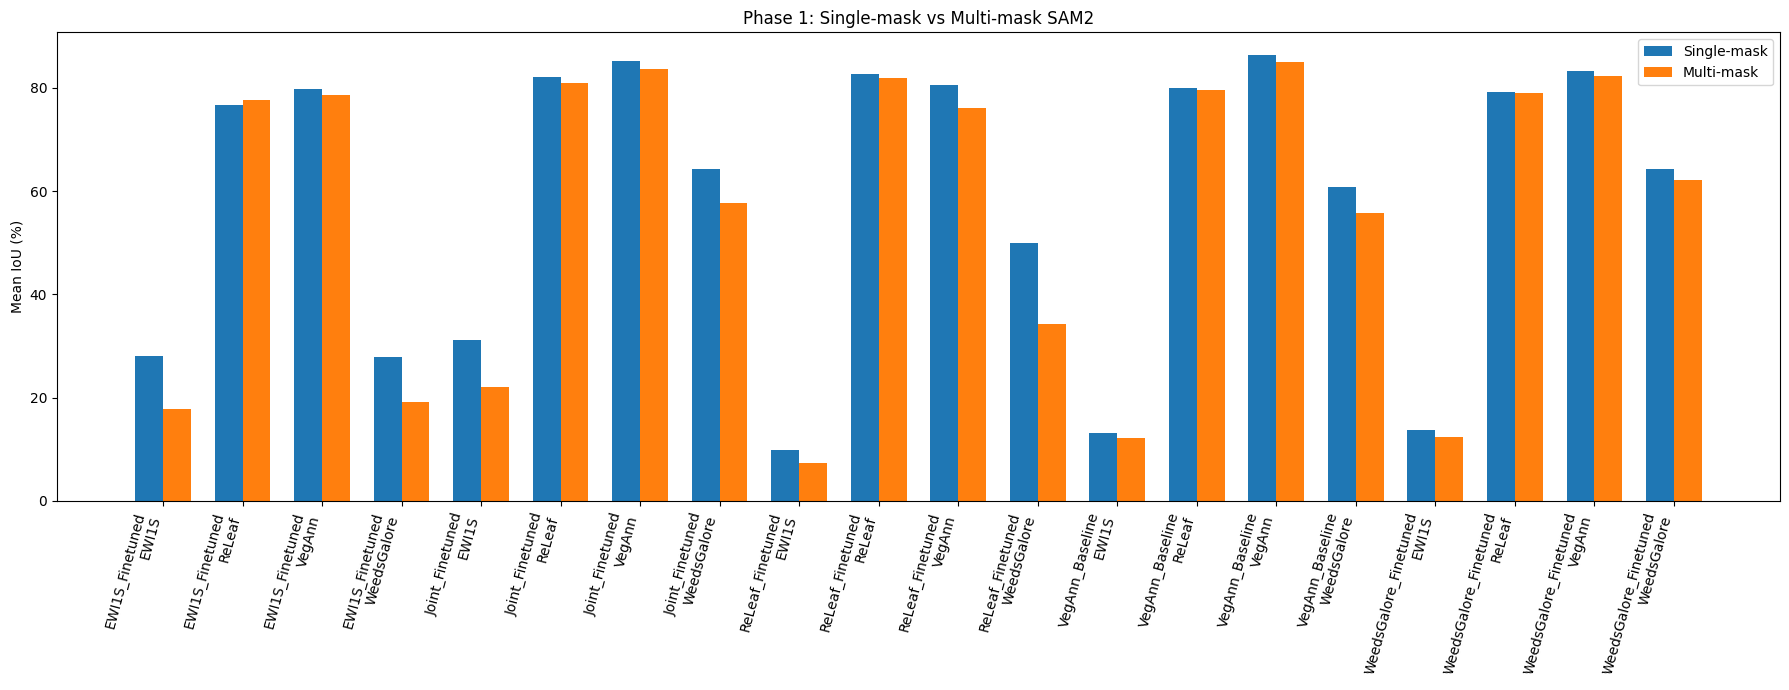

In [58]:
# ============================================================
# SINGLE VS MULTI-MASK IoU
# ============================================================

plot_df = summary_df.copy()

plot_df["label"] = (
    plot_df["checkpoint"]
    + "\n"
    + plot_df["dataset"]
)

x = np.arange(
    len(plot_df)
)

width = 0.35

plt.figure(
    figsize=(18, 7)
)

plt.bar(
    x - width / 2,
    plot_df["single_iou"],
    width,
    label="Single-mask"
)

plt.bar(
    x + width / 2,
    plot_df["multi_iou"],
    width,
    label="Multi-mask"
)

plt.xticks(
    x,
    plot_df["label"],
    rotation=75,
    ha="right"
)

plt.ylabel(
    "Mean IoU (%)"
)

plt.title(
    "Phase 1: Single-mask vs Multi-mask SAM2"
)

plt.legend()

plt.tight_layout()

plt.show()

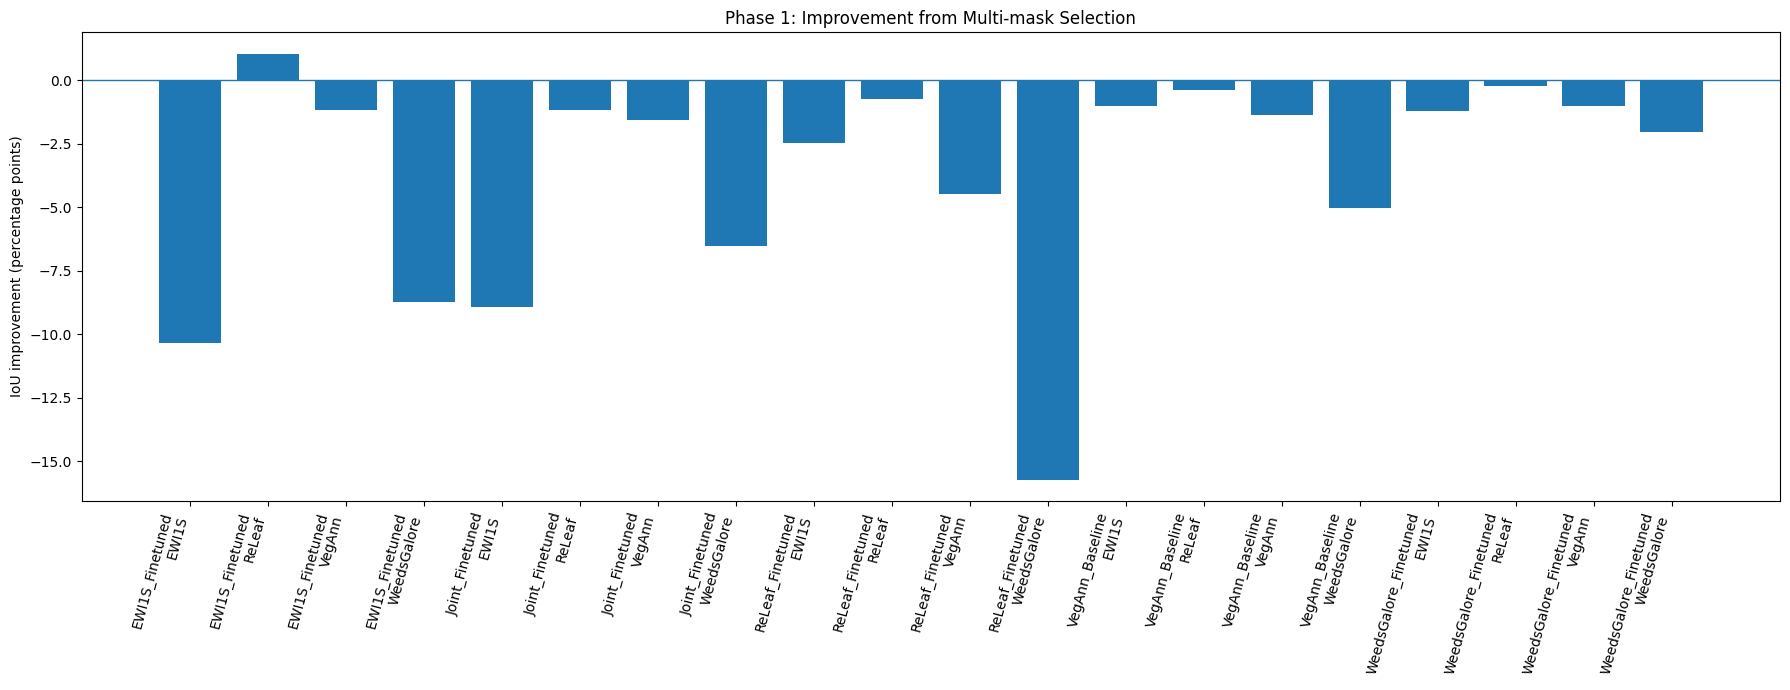

In [59]:
# ============================================================
# MULTI-MASK IoU IMPROVEMENT
# ============================================================

plt.figure(
    figsize=(18, 7)
)

plt.bar(
    np.arange(
        len(summary_df)
    ),
    summary_df[
        "IoU_improvement_pp"
    ]
)

plt.axhline(
    0,
    linewidth=1
)

plt.xticks(
    np.arange(
        len(summary_df)
    ),
    (
        summary_df["checkpoint"]
        + "\n"
        + summary_df["dataset"]
    ),
    rotation=75,
    ha="right"
)

plt.ylabel(
    "IoU improvement (percentage points)"
)

plt.title(
    "Phase 1: Improvement from Multi-mask Selection"
)

plt.tight_layout()

plt.show()

In [60]:
# ============================================================
# THESIS-READY PHASE 1 TABLE
# ============================================================

thesis_phase1_table = summary_df[
    [
        "checkpoint",
        "dataset",
        "images",
        "box_iou",
        "single_iou",
        "multi_iou",
        "IoU_improvement_pp",
        "single_dice_%",
        "multi_dice_%",
        "Dice_improvement_pp"
    ]
].copy()


thesis_phase1_table = (
    thesis_phase1_table
    .round(2)
)


print(
    "PHASE 1 — THESIS SUMMARY"
)

display(
    thesis_phase1_table
)

PHASE 1 — THESIS SUMMARY


,checkpoint,dataset,images,box_iou,single_iou,multi_iou,IoU_improvement_pp,single_dice_%,multi_dice_%,Dice_improvement_pp
0,EWI1S_Finetuned,EWI1S,8,95.62,28.07,17.71,-10.36,39.45,26.04,-13.41
1,EWI1S_Finetuned,ReLeaf,34,87.37,76.67,77.71,1.05,85.26,85.98,0.72
2,EWI1S_Finetuned,VegAnn,746,94.82,79.84,78.67,-1.17,87.23,86.63,-0.60
3,EWI1S_Finetuned,WeedsGalore,15,95.66,27.88,19.15,-8.73,40.81,31.21,-9.61
4,Joint_Finetuned,EWI1S,8,95.62,31.07,22.15,-8.92,43.63,32.08,-11.56
5,Joint_Finetuned,ReLeaf,34,87.37,82.19,81.01,-1.18,89.81,88.90,-0.91
6,Joint_Finetuned,VegAnn,746,94.82,85.18,83.62,-1.56,91.21,90.24,-0.98
7,Joint_Finetuned,WeedsGalore,15,95.66,64.22,57.71,-6.51,77.87,72.85,-5.01
8,ReLeaf_Finetuned,EWI1S,8,95.62,9.91,7.42,-2.49,13.81,11.57,-2.25
9,ReLeaf_Finetuned,ReLeaf,34,87.37,82.59,81.87,-0.73,89.97,89.47,-0.51
